# Etapa 2 · Cuaderno de trabajo: ciclo metodológico completo

**Proyecto:** predicción del ganador en carreras de caballos de Hong Kong con *machine learning* clásico sobre datos tabulares (Track A). Dataset de Kaggle `gdaley/hkracing`: 79 447 filas (un caballo en una carrera), 6 348 carreras, de 1997 a 2005.

Este es el cuaderno único de la etapa. Reúne el ciclo completo en tres partes que se ejecutan en orden:

| Parte | Qué muestra | Criterio de la rúbrica |
|---|---|---|
| **1 · Datos** | De los CSV originales a `dataset_v1`: qué se descarta por fuga, limpieza, partición cronológica, historial y pruebas de fuga | Pipeline y prevención de *leakage* |
| **2 · Modelos y resultados** | Baselines y escalera de modelos, búsqueda de hiperparámetros, curvas de aprendizaje, calibración, análisis de errores, v0 vs. v1 y test | Baselines · Entrenamiento y optimización · Análisis de resultados |
| **3 · Explicabilidad** | SHAP sobre el modelo propuesto (LambdaMART) y su uso como control de calidad | Explicabilidad |

La numeración de secciones es propia de cada parte: «Parte 2, sección 3» es la sección 3 dentro de la Parte 2.

**Qué hace y qué no hace el cuaderno.** La Parte 1 reconstruye la tabla desde los CSV con las funciones de `src/`. La Parte 2 **no entrena**: lee lo que `scripts/run_experiments.py` dejó en `results/`. La Parte 3 carga el modelo guardado y solo reentrena LambdaMART en las pruebas de control de calidad (sección 5).

**Requisitos para ejecutarlo completo** (desde la raíz del repo, con `data/raw/races.csv` y `data/raw/runs.csv` descargados):

```bash
pip install -r requirements.txt
python src/build_dataset.py --version v1
python scripts/run_experiments.py --data data/processed/dataset_v1.parquet --stage dev
# opcional, para la comparación sin historial (Parte 2, sección 6):
python src/build_dataset.py --version v0
python scripts/run_experiments.py --data data/processed/dataset_v0.parquet --stage dev --out results_v0
```

La documentación escrita está en `README.md`, `README_modelos.md` y `docs/`. La declaración de uso de IA está en `DECLARACION_IA.md`.

# Parte 1 · Datos: carga, limpieza, partición, historial y pruebas de fuga

Esta parte arma, paso a paso, la tabla que consumen los modelos: **una fila por caballo en cada carrera**, solo con información que se conoce antes de la salida. Usa las mismas funciones de `src/` que usa `src/build_dataset.py`, así que lo que se ve aquí es lo que realmente se entrega. **No escribe nada en disco.**

Responde las preguntas que el enunciado pide documentar sobre el *pipeline* y la prevención de *data leakage*: cómo se particionó, por qué esa proporción, si la partición es aleatoria o cronológica, y qué variables se descartaron por riesgo de fuga. El detalle escrito está en `docs/particion_y_fuga.md` y `docs/historial_v1.md`.

**Requisito:** `data/raw/races.csv` y `data/raw/runs.csv` (dataset de Kaggle `gdaley/hkracing`). Para guardar la tabla en `data/processed/`:

```bash
python src/build_dataset.py --version v1
```

In [31]:
import contextlib
import io
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Raíz del repo (sirve si el cuaderno se abre desde notebooks/ o desde la raíz)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "cleaning.py").is_file())
RAW = ROOT / "data" / "raw"
sys.path.insert(0, str(ROOT / "src"))
import cleaning as C
import history as H
from data_dictionary import NON_FEATURES, feature_columns

AZUL, NARANJA, GRIS = "#1f4e79", "#c55a11", "#7f7f7f"   # mismos colores en todo el cuaderno

## 1. Carga y variables descartadas por fuga

**Regla:** una variable solo puede entrar al modelo si su valor se conoce **antes de que empiece la carrera**. Todo lo que se genera durante o después (tiempos, posiciones por tramo, márgenes, dividendos, combinaciones ganadoras) se llama aquí columna **POST** y se borra.

Los patrones que las reconocen están en `cleaning.FORBIDDEN_PATTERNS`. El borrado se hace al leer cada CSV, **antes de unir** carreras con corredores.

In [32]:
runs_raw = pd.read_csv(RAW / "runs.csv")
races_raw = pd.read_csv(RAW / "races.csv")

for nombre, tabla in [("runs.csv", runs_raw), ("races.csv", races_raw)]:
    post = C.forbidden_columns(tabla.columns)
    print(f"{nombre}: {tabla.shape[0]:,} filas × {tabla.shape[1]} columnas → {len(post)} columnas POST que se borran:")
    print("   " + ", ".join(post) + "\n")

runs.csv: 79,447 filas × 37 columnas → 20 columnas POST que se borran:
   lengths_behind, position_sec1, position_sec2, position_sec3, position_sec4, position_sec5, position_sec6, behind_sec1, behind_sec2, behind_sec3, behind_sec4, behind_sec5, behind_sec6, time1, time2, time3, time4, time5, time6, finish_time

races.csv: 6,349 filas × 37 columnas → 26 columnas POST que se borran:
   sec_time1, sec_time2, sec_time3, sec_time4, sec_time5, sec_time6, sec_time7, time1, time2, time3, time4, time5, time6, time7, place_combination1, place_combination2, place_combination3, place_combination4, place_dividend1, place_dividend2, place_dividend3, place_dividend4, win_combination1, win_dividend1, win_combination2, win_dividend2



In [33]:
# ¿Por qué antes del join? Si se unieran las tablas tal cual, cada corredor heredaría
# las columnas de resultado de su carrera. Ejemplo con una sola de ellas:
j = runs_raw.merge(races_raw[["race_id", "win_combination1"]], on="race_id")
regla = (j["horse_no"] == j["win_combination1"]).astype(int)
print(f"La regla 'horse_no == win_combination1' coincide con la columna won "
      f"en el {100 * (regla == j['won']).mean():.2f} % de las {len(j):,} filas.")

La regla 'horse_no == win_combination1' coincide con la columna won en el 99.98 % de las 79,447 filas.


`win_combination1` es el número del caballo ganador: con esa sola columna copiada por el join, un modelo "acertaría" casi todo sin aprender nada. Por eso `merge()` se niega a unir si alguna de las dos tablas todavía trae una columna POST.

Además de las columnas borradas, hay columnas que **se conservan pero nunca son features** (`NON_FEATURES`):

| Columna | Por qué no es feature |
|---|---|
| `result` | Posición de llegada. Se guarda solo para calcular los targets |
| `won`, `y_rel` | Los targets |
| `win_odds`, `place_odds` | Cuotas finales del mercado: se fijan al cerrar las apuestas. `win_odds` se usa solo como referencia externa (baseline de mercado) en la Parte 2 |
| `race_id`, `date`, `horse_id`, `horse_no`, `race_no`, `split` | Identificadores y etiqueta de partición |

## 2. Limpieza

No se borra ninguna fila: quitar un corredor cambiaría el tamaño del campo y la estructura de un ganador por carrera. Los valores imposibles se anulan a NaN, sin reemplazarlos.

In [34]:
races, runs = C.load_races(RAW), C.load_runs(RAW)     # cada CSV ya sin columnas POST
df = C.merge(runs, races)                             # une por race_id
df, correcciones = C.prepare(df)                      # field_size, ids como texto, imposibles → NaN

print(f"\nCorredores antes y después de la limpieza: {len(runs_raw):,} → {len(df):,}")
print("Las dos filas corregidas, con su valor original:")
malos = (runs_raw["declared_weight"] < C.MIN_DECLARED_WEIGHT) | (runs_raw["draw"] > C.MAX_DRAW)
runs_raw.loc[malos, ["race_id", "horse_no", "horse_id", "declared_weight", "draw"]]

Corregido -> NaN: declared_weight < 850 (1 filas).
Corregido -> NaN: draw > 14 (1 filas).

Corredores antes y después de la limpieza: 79,447 → 79,447
Las dos filas corregidas, con su valor original:


,race_id,horse_no,horse_id,declared_weight,draw
28595,2287,4,2931,693.0000,12
64919,5188,3,4024,1054.0000,15


- **`declared_weight` = 693 lb:** es un error de registro (los siguientes valores más bajos del dataset rondan las 900 lb).
- **`draw` = 15:** ninguna carrera del dataset tiene más de 14 corredores, así que el cajón 15 no existe.

**Valores faltantes.** Aquí no se imputa ni se escala nada. Calcular una media o una mediana con toda la tabla antes de particionar metería información de validación y test en train, y eso es fuga. Los NaN se dejan como están y los trata el *pipeline* de cada modelo, ajustado solo con train (`src/hkr/preprocess.py`).

In [35]:
v0 = C.sort_by_race(C.add_split(C.add_targets(df)))   # targets, partición y orden cronológico
C.validate(v0)                                        # se detiene con DataError si algo no cumple

feats_v0 = feature_columns(v0.columns)
faltan = v0[feats_v0].isna().groupby(v0["split"]).sum().T[["train", "val", "test"]]
faltan = faltan[faltan.sum(axis=1) > 0]
faltan["% de train"] = (100 * faltan["train"] / (v0["split"] == "train").sum()).round(2).astype(str)
print(f"{len(feats_v0)} features en la tabla sin historial; faltantes por partición (número de filas):")
faltan

19 features en la tabla sin historial; faltantes por partición (número de filas):


split,train,val,test,% de train
horse_country,2,0,0,0.0
horse_type,2,0,0,0.0
declared_weight,1,0,0,0.0
draw,0,1,0,0.0
prize,5849,0,0,9.19


El único faltante grande es `prize` (cerca del 9 % de train). No es aleatorio: falta en un bloque de carreras de 1997–1998, por cómo se recolectaron los datos. En validación y test está completo.

## 3. Targets, desbalance y partición

Los targets se calculan desde `result`, fila por fila, sin usar estadísticas de otras filas:

- **`won`**: 1 si el caballo llegó primero.
- **`y_rel`**: 3 ganó · 2 llegó 2.º–3.º · 1 llegó 4.º–6.º · 0 el resto (lo usa el modelo de *ranking*).

In [36]:
campo = v0.groupby("race_id")["won"].agg(corredores="size", ganadores="sum")
print(f"Tasa de victoria por fila: {100 * v0['won'].mean():.2f} %")
print(f"Corredores por carrera: de {campo['corredores'].min()} a {campo['corredores'].max()} "
      f"(mediana {campo['corredores'].median():.0f})")
print(f"Carreras con empate en el primer lugar (dos ganadores): {(campo['ganadores'] > 1).sum()}")
print(f"Carreras sin ganador: {(campo['ganadores'] < 1).sum()}")
(100 * v0["y_rel"].value_counts(normalize=True).sort_index(ascending=False)).round(1).astype(str).rename("% de filas").to_frame().T

Tasa de victoria por fila: 8.01 %
Corredores por carrera: de 4 a 14 (mediana 12)
Carreras con empate en el primer lugar (dos ganadores): 12
Carreras sin ganador: 0


y_rel,3,2,1,0
% de filas,8.0,16.0,24.0,52.0


**El desbalance es estructural.** Solo el 8 % de las filas son ganadores porque hay un ganador por carrera de unos 12 caballos; no es un defecto del muestreo. Dos consecuencias para la Parte 2:

- *Accuracy* por fila no sirve: decir "ningún caballo gana" acierta el 92 % de las filas.
- Las métricas se calculan **por carrera** (¿el modelo eligió al ganador?), y no se usa sobremuestreo ni pesos por clase.

### Partición cronológica

In [37]:
orden = ["train", "val", "test"]
g = v0.groupby("split")
part = pd.DataFrame({
    "filas": g.size(), "% filas": (100 * g.size() / len(v0)).round(1).astype(str),
    "carreras": g["race_id"].nunique(),
    "% carreras": (100 * g["race_id"].nunique() / v0["race_id"].nunique()).round(1).astype(str),
    "desde": g["date"].min().dt.date, "hasta": g["date"].max().dt.date,
    "tasa de victoria %": (100 * g["won"].mean()).round(2).astype(str),
}).loc[orden]

# Las dos condiciones que hacen que la partición no tenga fuga temporal
assert (v0.groupby("race_id")["split"].nunique() == 1).all()                 # ninguna carrera queda en dos particiones
assert part.loc["train", "hasta"] < part.loc["val", "desde"] and part.loc["val", "hasta"] < part.loc["test", "desde"]
print(f"Total: {len(v0):,} filas, {v0['race_id'].nunique():,} carreras. "
      "Ninguna carrera cruza particiones y train < val < test en fechas.")
part

Total: 79,447 filas, 6,348 carreras. Ninguna carrera cruza particiones y train < val < test en fechas.


,filas,% filas,carreras,% carreras,desde,hasta,tasa de victoria %
split,,,,,,,
train,63668,80.1,5089,80.2,1997-06-02,2003-12-31,8.01
val,9902,12.5,789,12.4,2004-01-04,2004-12-29,7.98
test,5877,7.4,470,7.4,2005-01-01,2005-08-28,8.01


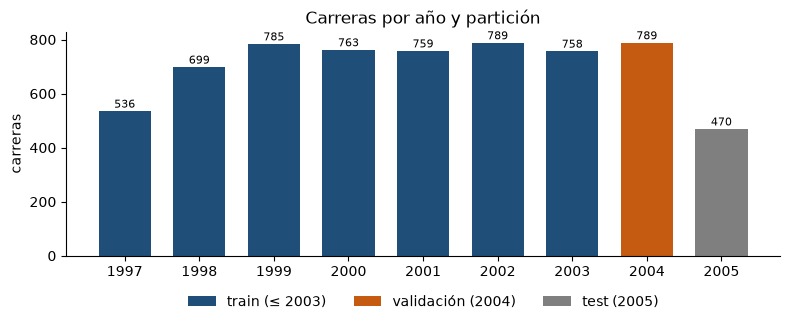

In [38]:
por_año = v0.groupby(v0["date"].dt.year).agg(carreras=("race_id", "nunique"), split=("split", "first"))
color = {"train": AZUL, "val": NARANJA, "test": GRIS}
nombre = {"train": "train (≤ 2003)", "val": "validación (2004)", "test": "test (2005)"}

fig, ax = plt.subplots(figsize=(8, 3.4))
for s in orden:
    d = por_año[por_año["split"] == s]
    ax.bar(d.index, d["carreras"], width=0.7, color=color[s], label=nombre[s])
for año, n in por_año["carreras"].items():
    ax.text(año, n + 12, str(n), ha="center", fontsize=8)
ax.set_xticks(por_año.index)
ax.set_ylabel("carreras")
ax.set_title("Carreras por año y partición")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

**Por qué cronológica y no aleatoria.**

1. Es como se usaría el modelo: siempre se predicen carreras futuras con lo que pasó antes. Una partición aleatoria pondría en train carreras posteriores a las de test (fuga temporal).
2. El historial de la sección 4 se calcula con carreras anteriores. Con una partición aleatoria, el historial de una fila de train podría incluir carreras de test.
3. Se asigna la **carrera** completa a una partición, no la fila: si los rivales de una carrera de test estuvieran en train, el modelo vería parte de su resultado.

**Por qué esta proporción.** Son bloques de un año calendario, fáciles de auditar (la regla es comparar el año). Validación es 2004 completo, test es 2005, el año más reciente y el más parecido a "producción", y train son los 6.5 años anteriores (≈ 80 %), que el historial necesita para acumular carreras por caballo, jinete y entrenador. La tasa de victoria es la misma en las tres particiones (≈ 8 %).

**Limitaciones asumidas.** El corte por año calendario parte una temporada (en Hong Kong va de septiembre a julio), y test llega solo hasta agosto de 2005: con 470 carreras, sus métricas tienen más varianza que las de validación. La literatura que respalda la partición temporal y el detalle de cada decisión están en `docs/particion_y_fuga.md` (§2).

## 4. Historial (`dataset_v1`)

`dataset_v0` describe al caballo y la carrera, pero no dice cómo le ha ido antes. `dataset_v1` agrega cinco variables de historial:

| Variable | Qué es | Sin carreras previas |
|---|---|---|
| `horse_win_rate`, `jockey_win_rate`, `trainer_win_rate` | Tasa de victoria previa del caballo, del jinete y del entrenador | Vale el *prior* |
| `horse_days_since_last` | Días desde la carrera anterior del caballo | NaN |
| `horse_no_history` | 1 si es la primera carrera del caballo en el dataset | — |

**Regla contra fuga:** cada fila usa solo carreras de **fechas anteriores**. Las del mismo día tampoco cuentan, porque un jinete corre varias carreras por jornada y la primera no puede conocer el resultado de la tercera.

**Shrinkage.** Un caballo que ganó su única carrera tendría una tasa de 100 %, que no es creíble. La tasa se acerca al promedio general cuando hay pocas carreras:

$$\text{tasa} = \frac{\text{victorias previas} + k \cdot \text{prior}}{\text{carreras previas} + k}$$

El *prior* es la tasa de victoria de **train**. La constante *k* se elige por entidad en **validación** (menor *log loss* usando la tasa como probabilidad de ganar). Test no participa en ninguno de los dos.

In [39]:
with contextlib.redirect_stdout(io.StringIO()):       # sin repetir los mensajes de limpieza de arriba
    v1, _, fit = H.build_v1(RAW)                      # la misma función que usa build_dataset.py

# v1 no cambia nada de lo construido arriba: mismas filas, mismos valores, mismo orden
comunes = [c for c in v0.columns if c in v1.columns]
pd.testing.assert_frame_equal(v1[comunes], v0[comunes])

feats_v1 = feature_columns(v1.columns)
print(f"prior (tasa de victoria en train) = {fit['prior']:.4f}")
print(f"k elegido en validación: {fit['k']}")
print(f"\nv0: {len(feats_v0)} features → v1: {len(feats_v1)} features")
print(f"  entran: {H.NEW_FEATURES}")
print(f"  salen:  {list(H.REPLACED)} (reemplazadas por {list(H.REPLACED.values())})")

prior (tasa de victoria en train) = 0.0801
k elegido en validación: {'horse': 100, 'jockey': 50, 'trainer': 500}

v0: 19 features → v1: 22 features
  entran: ['horse_win_rate', 'jockey_win_rate', 'trainer_win_rate', 'horse_days_since_last', 'horse_no_history', 'gear_any']
  salen:  ['jockey_id', 'trainer_id', 'horse_gear'] (reemplazadas por ['jockey_win_rate', 'trainer_win_rate', 'gear_any'])


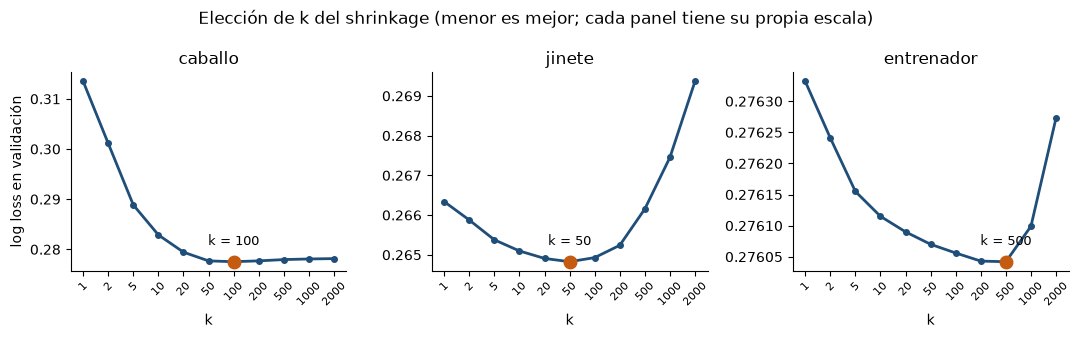

Sin shrinkage (k = 0, fuera del gráfico): {'caballo': 0.5628, 'jinete': 0.2746, 'entrenador': 0.2783}


In [40]:
busq = fit["search"]
titulos = {"horse": "caballo", "jockey": "jinete", "trainer": "entrenador"}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (ent, titulo) in zip(axes, titulos.items()):
    d = busq[(busq["entidad"] == ent) & (busq["k"] > 0)].reset_index(drop=True)
    ax.plot(d.index, d["log_loss_val"], "o-", color=AZUL, lw=2, ms=4)
    i = int(d.index[d["k"] == fit["k"][ent]][0])
    ax.plot(i, d.loc[i, "log_loss_val"], "o", color=NARANJA, ms=9)
    ax.annotate(f"k = {fit['k'][ent]}", (i, d.loc[i, "log_loss_val"]), textcoords="offset points",
                xytext=(0, 12), ha="center", fontsize=9)
    ax.set_xticks(d.index, d["k"], fontsize=8, rotation=45)
    ax.set_title(titulo); ax.set_xlabel("k")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("log loss en validación")
plt.suptitle("Elección de k del shrinkage (menor es mejor; cada panel tiene su propia escala)")
plt.tight_layout(); plt.show()

print("Sin shrinkage (k = 0, fuera del gráfico):",
      busq[busq["k"] == 0].set_index("entidad")["log_loss_val"].rename(titulos).round(4).to_dict())

**Cómo leerlo.** Para el caballo, la tasa sin *shrinkage* es muy mala (la mayoría tiene pocas carreras) y mejora mucho al acercarla al promedio. Para el jinete hay un mínimo claro. Para el entrenador la curva es casi plana: su *k* es prácticamente indiferente.

**Por qué tasas y no los identificadores.** En v1 la tasa histórica reemplaza a `jockey_id` y `trainer_id`: se actualiza con cada carrera y un jinete nuevo empieza en el promedio en vez de ser desconocido para el modelo. `horse_gear` tiene cientos de combinaciones con poca señal y queda como `gear_any` (lleva o no algún equipo). El detalle está en `docs/historial_v1.md`.

**Ejemplo.** Las primeras carreras de un caballo que ganó en su debut: la victoria no aparece en la fila de esa carrera, sino a partir de la siguiente.

In [41]:
debut_ganador = v1.loc[(v1["horse_no_history"] == 1) & (v1["won"] == 1), "horse_id"].iloc[0]
h = v1.loc[v1["horse_id"] == debut_ganador,
           ["date", "won", "horse_no_history", "horse_days_since_last", "horse_win_rate"]].head(6).copy()

# La misma tasa calculada a mano con la fórmula, usando solo las filas de arriba de cada una
k, prior = fit["k"]["horse"], fit["prior"]
previas, victorias = pd.Series(range(len(h)), index=h.index), h["won"].cumsum().shift(1, fill_value=0)
h["tasa a mano"] = (victorias + k * prior) / (previas + k)
assert (h["tasa a mano"] - h["horse_win_rate"]).abs().max() < 1e-12
print(f"Caballo {debut_ganador} · prior = {prior:.4f} · k = {k}")
h

Caballo 2170 · prior = 0.0801 · k = 100


,date,won,horse_no_history,horse_days_since_last,horse_win_rate,tasa a mano
7,1997-06-02,1,1,NaN,0.0801,0.0801
249,1997-06-08,0,0,6.0000,0.0892,0.0892
587,1997-06-18,0,0,10.0000,0.0883,0.0883
1581,1997-07-20,1,0,32.0000,0.0875,0.0875
2419,1997-08-17,0,0,28.0000,0.0962,0.0962
3081,1997-09-06,0,0,20.0000,0.0953,0.0953


## 5. Pruebas de fuga

Las reglas anteriores no se dejan a la confianza: `tests/` tiene pruebas automáticas que fallan si alguna se rompe. Aquí se muestran en vivo los dos controles principales y luego se corre la batería completa.

### 5.1 El historial solo usa el pasado (prueba de perturbación)

Se invierten todos los resultados desde el primer día de validación y se recalcula el historial. Si una variable de una fila anterior cambiara, querría decir que leyó resultados del mismo día o del futuro.

In [42]:
corte = v0.loc[v0["split"] == "val", "date"].min()
alterado = v0.copy()
futuro = alterado["date"] >= corte
alterado.loc[futuro, "won"] = 1 - alterado.loc[futuro, "won"]         # ganadores y perdedores invertidos

real = H.history_features(v0, fit["k"], fit["prior"])
alt = H.history_features(alterado, fit["k"], fit["prior"])

pasado = v0["date"] <= corte                                          # incluye el propio día del corte
pd.testing.assert_frame_equal(real[pasado], alt[pasado])
tasas = ["horse_win_rate", "jockey_win_rate", "trainer_win_rate"]
cambian = (real.loc[~pasado, tasas] != alt.loc[~pasado, tasas]).any(axis=1)
print(f"Corte: {corte.date()}")
print(f"  filas con fecha ≤ corte: {pasado.sum():,} → cambió alguna variable de historial en 0")
print(f"  filas posteriores:       {(~pasado).sum():,} → cambió alguna tasa en {cambian.sum():,}")

Corte: 2004-01-04
  filas con fecha ≤ corte: 63,803 → cambió alguna variable de historial en 0
  filas posteriores:       15,644 → cambió alguna tasa en 15,611


Las filas anteriores al corte no cambian, y casi todas las posteriores sí: el historial reacciona a los resultados previos, pero nunca a los del mismo día ni a los futuros. El test `test_features_historicas_de_v1_usan_solo_el_pasado` repite esto con cuatro cortes (dos dentro de train, el primer día de validación y el primer día de test).

Las filas de validación y test sí usan carreras anteriores de su misma partición. No es fuga: cuando se predice una carrera de 2005, las de los días previos de 2005 ya ocurrieron.

### 5.2 Ninguna variable "sabe" el resultado

Una variable con fuga ordenaría a los caballos de una carrera casi igual que el resultado. Se mide la correlación de Spearman entre cada variable numérica y la posición de llegada **dentro de cada carrera**. Como control positivo se incluye `win_odds`, la cuota final del mercado, que no es variable del modelo: si el control no la detectara, no serviría para detectar nada.

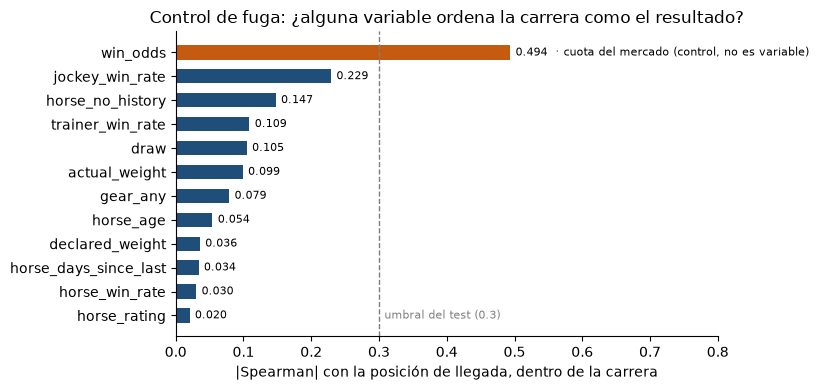

In [43]:
sys.path.insert(0, str(ROOT / "tests"))
from test_leakage_v0 import MAX_RHO, _rho_en_carrera              # la misma medida y el mismo umbral que usan los tests

numericas = [c for c in feats_v1 if pd.api.types.is_numeric_dtype(v1[c])]
rho = pd.Series({c: _rho_en_carrera(v1, c) for c in numericas + ["win_odds"]}).abs().dropna().sort_values()
assert rho.drop("win_odds").max() < MAX_RHO < rho["win_odds"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(rho.index, rho, height=0.6, color=[NARANJA if c == "win_odds" else AZUL for c in rho.index])
for i, (c, x) in enumerate(rho.items()):
    nota = "  · cuota del mercado (control, no es variable)" if c == "win_odds" else ""
    ax.text(x + 0.008, i, f"{x:.3f}{nota}", va="center", fontsize=8)
ax.axvline(MAX_RHO, ls="--", color=GRIS, lw=1)
ax.text(MAX_RHO + 0.008, 0, f"umbral del test ({MAX_RHO})", color=GRIS, fontsize=8, va="center")
ax.set_xlabel("|Spearman| con la posición de llegada, dentro de la carrera")
ax.set_xlim(0, 0.8)
ax.set_title("Control de fuga: ¿alguna variable ordena la carrera como el resultado?")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Cómo leerlo.** Ninguna variable se acerca al umbral ni a la cuota del mercado. La más alta es `jockey_win_rate`, y tiene sentido que sea informativa: los mejores jinetes montan mejores caballos. Las variables de la carrera (`distance`, `prize`, `race_class`, `surface`, `field_size`) no aparecen porque valen lo mismo para todos los corredores de una carrera y no pueden ordenarla.

Es una heurística: no descarta una fuga débil por debajo del umbral. Por eso se complementa con la revisión variable por variable (`docs/particion_y_fuga.md`, §4) y con SHAP en la Parte 3, que busca variables inesperadas que dominen el modelo.

### 5.3 Batería completa de tests de datos

In [44]:
archivos = ["test_cleaning_unit.py", "test_leakage_v0.py", "test_dataset_v1.py", "test_leakage_checks.py"]
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", *[f"tests/{a}" for a in archivos]],
                   cwd=ROOT, capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])
assert r.returncode == 0, r.stdout[-2000:]

78 passed in 6.22s


| Tipo de fuga | Qué verifican los tests |
|---|---|
| *Target leakage* | Los patrones reconocen exactamente las 20 + 26 columnas POST; la tabla final no trae ninguna; cada columna original o se conserva o se borra con motivo; las features son las revisadas una por una |
| Fuga temporal | La partición sigue la regla por año, ninguna carrera cruza particiones, train < val < test; el historial solo usa fechas anteriores |
| Fuga por preprocesamiento | Cada valor de la tabla es el original salvo las dos correcciones a NaN (nada imputado ni escalado antes de particionar); el *prior* y los *k* no cambian si se alteran los resultados de test |

En `docs/particion_y_fuga.md` (§5.1) y `docs/historial_v1.md` (§4) se documenta además que, al sabotear a propósito las protecciones, los tests fallan.

## 6. Salida

La tabla construida en esta parte es la misma que está guardada y que leen las Partes 2 y 3.

In [45]:
guardada = ROOT / "data" / "processed" / "dataset_v1.parquet"
if guardada.exists():
    pd.testing.assert_frame_equal(pd.read_parquet(guardada), v1, check_dtype=False)
    print(f"{guardada.relative_to(ROOT)} es idéntica a la tabla construida aquí.")
else:
    print("No existe data/processed/dataset_v1.parquet: generarla con  python src/build_dataset.py --version v1")

roles = pd.Series({c: NON_FEATURES.get(c, "feature") for c in v1.columns})
print(f"{v1.shape[0]:,} filas × {v1.shape[1]} columnas: {(roles == 'feature').sum()} features y {(roles != 'feature').sum()} que no entran al modelo")
print("features:", feats_v1)

data/processed/dataset_v1.parquet es idéntica a la tabla construida aquí.
79,447 filas × 33 columnas: 22 features y 11 que no entran al modelo
features: ['horse_age', 'horse_country', 'horse_type', 'horse_rating', 'declared_weight', 'actual_weight', 'draw', 'venue', 'config', 'surface', 'distance', 'going', 'horse_ratings', 'prize', 'race_class', 'field_size', 'horse_win_rate', 'jockey_win_rate', 'trainer_win_rate', 'horse_days_since_last', 'horse_no_history', 'gear_any']


## Resumen de la Parte 1

| Pregunta del enunciado | Respuesta | Dónde |
|---|---|---|
| ¿Cómo se particionó? | Por año de la carrera: train ≤ 2003, validación 2004, test 2005; la carrera completa va a una sola partición | §3, `cleaning.add_split` |
| ¿Aleatoria o cronológica, y por qué? | Cronológica: se predice el futuro con el pasado, y el historial lo exige | §3 |
| ¿Por qué esa proporción? | Bloques de un año: ≈ 80 % / 12 % / 7 % de las carreras, con la misma tasa de victoria | §3 |
| ¿Qué variables se descartaron por fuga? | 46 columnas POST (tiempos, posiciones por tramo, márgenes, dividendos, combinaciones). `result` y las cuotas se conservan pero no son features | §1 |
| ¿El preprocesamiento se ajusta solo con train? | Aquí no se imputa ni se escala nada. El *prior* del historial sale de train y *k* de validación. La imputación, el escalado y la codificación están en el *pipeline* de los modelos | §2, §4, `src/hkr/preprocess.py` |
| ¿Cómo se sabe que no hay fuga? | Prueba de perturbación, control contra la cuota del mercado y tests automáticos | §5 |

**Limitaciones que se arrastran a las siguientes partes.**

- *k* se eligió con validación (2004), igual que un hiperparámetro. Eso deja las métricas de validación levemente optimistas; test (2005) no participó y es la medición limpia.
- Que cada variable se conozca antes de la carrera es, para la mayoría, un supuesto razonable sobre cómo se publican los datos y no algo verificable con el dataset. La tabla de `docs/particion_y_fuga.md` (§4) marca cuáles están verificadas, cuáles son supuesto y cuál queda como riesgo abierto (`horse_age`).
- `prize` falta en un bloque de 1997–1998 y test es un año incompleto.

**Siguiente:** Parte 2, modelos y resultados.

# Parte 2 · Modelos, métricas y resultados

Esta parte **no entrena nada**: lee lo que deja `scripts/run_experiments.py` en `results/` y lo presenta en tablas y gráficos. Así cualquiera puede revisar los resultados sin esperar los 10-20 minutos de entrenamiento.

**Cómo regenerar los resultados desde cero** (desde la raíz del repo):

```bash
python src/build_dataset.py --version v1
python scripts/run_experiments.py --data data/processed/dataset_v1.parquet --stage dev
# opcional, para la comparación sin historial:
python src/build_dataset.py --version v0
python scripts/run_experiments.py --data data/processed/dataset_v0.parquet --stage dev --out results_v0
```

Todo lo que aparece aquí es **validación (2004)**. El test (2005) se evalúa una sola vez al final con `--stage final`; si ya se corrió, la última sección lo muestra.

In [46]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Raíz del repo: la carpeta que contiene results/ (sirve si el cuaderno se abre desde notebooks/ o desde la raíz)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").is_dir())
RES = ROOT / "results"
RES_V0 = ROOT / "results_v0"          # opcional
CFG = json.loads((ROOT / "configs" / "experiment.json").read_text(encoding="utf-8"))

val = pd.read_csv(RES / "val_metrics.csv").set_index("model")
info = json.loads((RES / "run_info.json").read_text())
feats = json.loads((RES / "features.json").read_text())
print(f"Corrida: {info['when']} · Python {info['python']} · semilla {info['seed']} · {info['n_rows']:,} filas")
print(f"{len(feats)} features: {feats}")

Corrida: 2026-11-15T18:38:10 · Python 3.12.3 · semilla 42 · 79,447 filas
22 features: ['horse_age', 'horse_country', 'horse_type', 'horse_rating', 'declared_weight', 'actual_weight', 'draw', 'venue', 'config', 'surface', 'distance', 'going', 'horse_ratings', 'prize', 'race_class', 'field_size', 'horse_win_rate', 'jockey_win_rate', 'trainer_win_rate', 'horse_days_since_last', 'horse_no_history', 'gear_any']


## 1. Escalera de modelos en validación (2004)

Cada escalón agrega una sola idea respecto al anterior (Sección IV-E del paper):

| Escalón | Qué agrega |
|---|---|
| `random` | Piso: elige al azar dentro del campo |
| `market` | Referencia externa: el favorito de las cuotas finales (no es feature) |
| `logreg` | Baseline simple: gana / no gana, caballo por caballo |
| `gbm_binary` | Lo mismo, con no linealidad (gradient boosting) |
| `clogit` | Normaliza dentro de la carrera: las probabilidades suman 1 |
| `lambdamart` | Aprende del orden completo de llegada (modelo propuesto) |

Todas las métricas se promedian **por carrera**, no por fila. Los intervalos son IC 95 % por *bootstrap* remuestreando carreras. `Δ vs mercado` es la diferencia **pareada** de top-1 contra el favorito, en las mismas carreras: si su IC incluye 0, no se puede afirmar que el modelo es distinto del mercado.

In [47]:
orden = ["random", "market", "logreg", "gbm_binary", "clogit", "lambdamart"]
v = val.reindex([m for m in orden if m in val.index])
pct = lambda x: f"{100*x:.1f}"
tabla = pd.DataFrame({
    "top-1 % [IC 95 %]": [f"{pct(r.top1)} [{pct(r.top1_lo)}–{pct(r.top1_hi)}]" for r in v.itertuples()],
    "Δ vs mercado (pp) [IC]": [
        "—" if pd.isna(r.top1_diff_vs_ref) else
        f"{100*r.top1_diff_vs_ref:+.1f} [{100*r.top1_diff_lo:+.1f}, {100*r.top1_diff_hi:+.1f}]"
        for r in v.itertuples()],
    "MRR": v["mrr"], "NDCG@3": v["ndcg@3"], "AUC intra": v["auc_race"],
    "log loss": v["log_loss"], "Brier": v["brier_race"], "ECE": v["ece"],
}, index=v.index)
tabla

,top-1 % [IC 95 %],Δ vs mercado (pp) [IC],MRR,NDCG@3,AUC intra,log loss,Brier,ECE
model,,,,,,,,
random,8.1 [8.0–8.2],"-25.0 [-28.2, -21.8]",0.2477,0.2599,0.4871,2.5228,0.9184,0.0001
market,33.1 [29.9–36.4],—,0.5235,0.5689,0.7859,1.9968,0.8117,0.0048
logreg,23.4 [20.5–26.6],"-9.6 [-13.1, -6.1]",0.4196,0.4614,0.6805,2.3310,0.8814,0.0073
gbm_binary,19.8 [17.0–22.7],"-13.3 [-16.9, -9.8]",0.4104,0.4567,0.6962,2.3121,0.8813,0.0055
clogit,22.8 [19.9–26.0],"-10.3 [-13.8, -6.7]",0.4144,0.4535,0.6744,2.3421,0.8838,0.0063
lambdamart,20.3 [17.6–23.2],"-12.8 [-16.4, -9.3]",0.4036,0.4467,0.6875,2.3133,0.8818,0.0085


**Referencias de literatura** (no son directamente comparables; ver la nota de cada una). Chavan et al. reportan *accuracy por fila* con partición aleatoria: un modelo que nunca predice ganador ya saca ~92 %, por eso no se compara contra nuestro top-1.

In [48]:
pd.DataFrame(CFG["literature"])

,source,metric,value,note
0,"Silverman (2012), Hong Kong, 2,973 carreras",top1,0.2160,"Predice el caballo más rápido estimado, no el ..."
1,"Chavan et al. (2024), mismo dataset de Kaggle",accuracy por fila,0.9200,Split aleatorio 80/20; el Dummy Classifier tam...


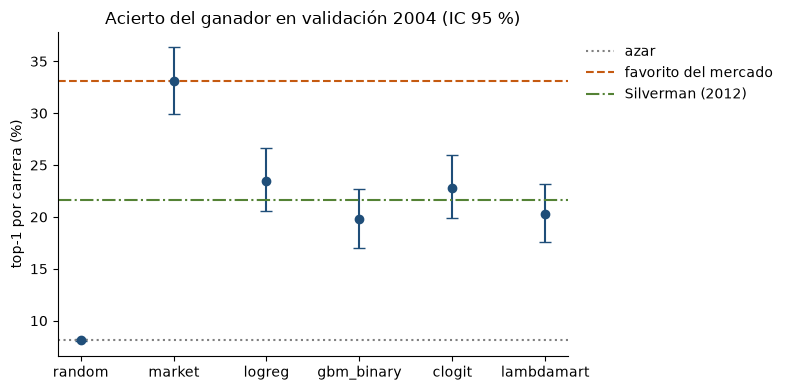

In [49]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(v))
ax.errorbar(x, 100 * v["top1"], yerr=[100 * (v["top1"] - v["top1_lo"]), 100 * (v["top1_hi"] - v["top1"])],
            fmt="o", capsize=4, color="#1f4e79")
ax.axhline(100 * v.loc["random", "top1"], ls=":", color="grey", label="azar")
ax.axhline(100 * v.loc["market", "top1"], ls="--", color="#c55a11", label="favorito del mercado")
silv = next((l["value"] for l in CFG["literature"] if l["source"].startswith("Silverman")), None)
if silv:
    ax.axhline(100 * silv, ls="-.", color="#548235", label="Silverman (2012)")
ax.set_xticks(list(x), v.index)
ax.set_ylabel("top-1 por carrera (%)")
ax.set_title("Acierto del ganador en validación 2004 (IC 95 %)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [50]:
modelos = v.drop(index=["random", "market"])
mejor = modelos["mrr"].idxmax()
print(f"Mejor modelo por MRR en validación: {mejor} (MRR {modelos.loc[mejor,'mrr']:.3f}, "
      f"top-1 {100*modelos.loc[mejor,'top1']:.1f} %)")
for m, r in modelos.iterrows():
    sig = "SÍ" if (r.top1_diff_hi < 0 or r.top1_diff_lo > 0) else "no"
    print(f"  {m:11s}: ¿distinto del mercado con IC 95 %? {sig}  (Δ {100*r.top1_diff_vs_ref:+.1f} pp)")

Mejor modelo por MRR en validación: logreg (MRR 0.420, top-1 23.4 %)
  logreg     : ¿distinto del mercado con IC 95 %? SÍ  (Δ -9.6 pp)
  gbm_binary : ¿distinto del mercado con IC 95 %? SÍ  (Δ -13.3 pp)
  clogit     : ¿distinto del mercado con IC 95 %? SÍ  (Δ -10.3 pp)
  lambdamart : ¿distinto del mercado con IC 95 %? SÍ  (Δ -12.8 pp)


## 2. Búsqueda de hiperparámetros

Protocolo (detalle y justificación en `docs/busqueda_hiperparametros.md`):

- **Optuna (TPE)** con semilla fija; todos los modelos con hiperparámetros se tunean con el mismo protocolo, no solo el propuesto.
- **Validación cruzada *forward chaining*** dentro de train: entrena ≤ 2000 / valida 2001, ≤ 2001 / 2002, ≤ 2002 / 2003. Nunca se baraja, y ni 2004 ni 2005 participan.
- **Objetivo:** MRR medio en los 3 folds (se reporta media ± desviación estándar).
- En los modelos de árboles el número de árboles sale de *early stopping* en los folds; el modelo final se reentrena con ese número fijo.

In [51]:
rows = []
for f in sorted((RES / "tuning").glob("*_best.json")):
    b = json.loads(f.read_text())
    rows.append({"modelo": b["model"], "pruebas": b["n_trials"], "folds": b["n_folds"],
                 "CV MRR": f"{b['best_cv_mrr']:.4f} ± {b['best_cv_mrr_std']:.4f}",
                 "CV top-1": f"{100*b['best_cv_top1']:.1f} ± {100*b['best_cv_top1_std']:.1f} %",
                 "segundos": b["seconds"], "s / prueba": b["seconds_per_trial"],
                 "mejores hiperparámetros": {k: (round(x, 4) if isinstance(x, float) else x)
                                             for k, x in b["best_params"].items()}})
tun = pd.DataFrame(rows).set_index("modelo")
print(f"Costo total de la búsqueda: {tun['segundos'].sum()/60:.1f} min")
tun

Costo total de la búsqueda: 5.3 min


,pruebas,folds,CV MRR,CV top-1,segundos,s / prueba,mejores hiperparámetros
modelo,,,,,,,
clogit,15,3,0.3858 ± 0.0197,19.2 ± 2.3 %,116.9000,7.8000,{'alpha': 0.0039}
gbm_binary,40,3,0.4005 ± 0.0128,21.0 ± 1.4 %,75.4000,1.8900,"{'learning_rate': 0.1476, 'num_leaves': 10, 'm..."
lambdamart,40,3,0.4079 ± 0.0163,21.6 ± 1.5 %,82.2000,2.0500,"{'learning_rate': 0.0935, 'num_leaves': 8, 'mi..."
logreg,15,3,0.3859 ± 0.0185,18.9 ± 2.0 %,43.9000,2.9300,{'C': 0.0022}


In [52]:
# ¿Algún hiperparámetro quedó pegado al borde del rango? Si sí, el óptimo podría estar afuera
# y hay que ampliar el rango en src/hkr/tuning.py (SEARCH_SPACE) y volver a correr.
import math, sys
sys.path.insert(0, str(ROOT / "src"))
from hkr.tuning import SEARCH_SPACE

filas = []
for m in tun.index:
    best = json.loads((RES / "tuning" / f"{m}_best.json").read_text())["best_params"]
    for p, (kind, lo, hi, log) in SEARCH_SPACE[m].items():
        x = best[p]
        f = (math.log(x) - math.log(lo)) / (math.log(hi) - math.log(lo)) if log else (x - lo) / (hi - lo)
        filas.append({"modelo": m, "hiperparámetro": p, "rango": f"[{lo:g}, {hi:g}]" + (" log" if log else ""),
                      "elegido": round(x, 5), "posición en el rango": f"{100*f:.0f} %",
                      "¿en el borde?": "⚠️ sí" if (f < 0.05 or f > 0.95) else "no"})
bordes = pd.DataFrame(filas)
print("Hiperparámetros en el 5 % extremo del rango:", (bordes["¿en el borde?"] != "no").sum())
print("Si alguno aparece en el borde, revisar en *_trials.csv si de verdad cambia el MRR "
      "(ver docs/busqueda_hiperparametros.md, sección 'Revisión de bordes').")
bordes

Hiperparámetros en el 5 % extremo del rango: 2
Si alguno aparece en el borde, revisar en *_trials.csv si de verdad cambia el MRR (ver docs/busqueda_hiperparametros.md, sección 'Revisión de bordes').


,modelo,hiperparámetro,rango,elegido,posición en el rango,¿en el borde?
0,clogit,alpha,"[1e-06, 1] log",0.0039,60 %,no
1,gbm_binary,learning_rate,"[0.01, 0.2] log",0.1476,90 %,no
2,gbm_binary,num_leaves,"[7, 127] log",10.0000,12 %,no
3,gbm_binary,min_child_samples,"[3, 300] log",6.0000,15 %,no
4,gbm_binary,colsample_bytree,"[0.4, 1]",0.8706,78 %,no
5,gbm_binary,subsample,"[0.5, 1]",0.7282,46 %,no
6,gbm_binary,reg_lambda,"[0.001, 30] log",1.7046,72 %,no
7,lambdamart,learning_rate,"[0.01, 0.2] log",0.0935,75 %,no
8,lambdamart,num_leaves,"[7, 127] log",8.0000,5 %,⚠️ sí
9,lambdamart,min_child_samples,"[3, 300] log",3.0000,0 %,⚠️ sí


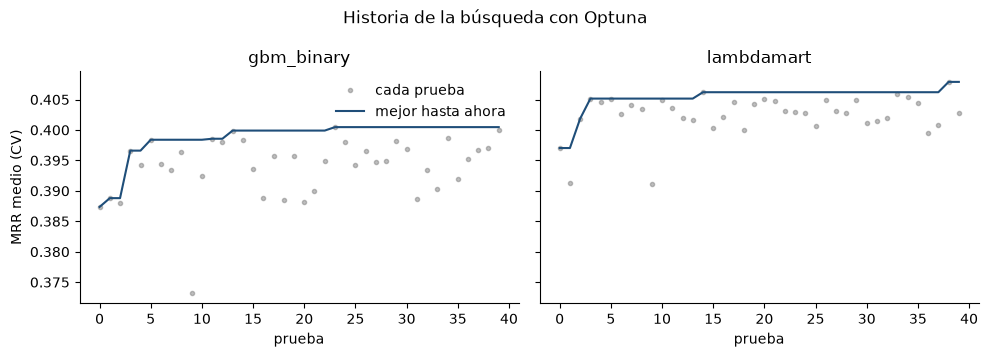

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, m in zip(axes, ["gbm_binary", "lambdamart"]):
    t = pd.read_csv(RES / "tuning" / f"{m}_trials.csv")
    ax.plot(t["number"], t["value"], "o", ms=3, alpha=.5, color="#7f7f7f", label="cada prueba")
    ax.plot(t["number"], t["value"].cummax(), color="#1f4e79", label="mejor hasta ahora")
    ax.set_title(m); ax.set_xlabel("prueba"); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("MRR medio (CV)"); axes[0].legend(frameon=False)
plt.suptitle("Historia de la búsqueda con Optuna"); plt.tight_layout(); plt.show()

**Cómo leerlo:** si la curva "mejor hasta ahora" se aplana mucho antes de la última prueba, más pruebas no habrían cambiado el resultado: el presupuesto de búsqueda fue suficiente.

## 3. Curvas de aprendizaje: ¿sobreajuste o subajuste?

Se entrena con los últimos *k* años de train (siempre los más recientes, para que la distancia a 2004 sea la misma) y se mide en train y en validación.

- **Brecha grande train − val** → sobreajuste (memoriza).
- **Val sube al agregar años** → más datos ayudarían.
- **Ambas bajas y planas** → subajuste.

**Ojo con val > train:** 2004 fue el año más predecible del período, incluso para el mercado (el favorito acertó 33.1 % en 2004, contra 29.3 % en los años de train y 26.2 % en 2001). Por eso un modelo que no sobreajusta puede salir mejor en validación que en train. Además, el *k* del *shrinkage* del historial se eligió en 2004, lo que deja la validación levemente optimista para todos los modelos por igual; el test (2005) no tiene ese sesgo.

logreg     : MRR train 0.380 vs val 0.420 → brecha -0.039 con todos los años
lambdamart : MRR train 0.451 vs val 0.404 → brecha +0.048 con todos los años


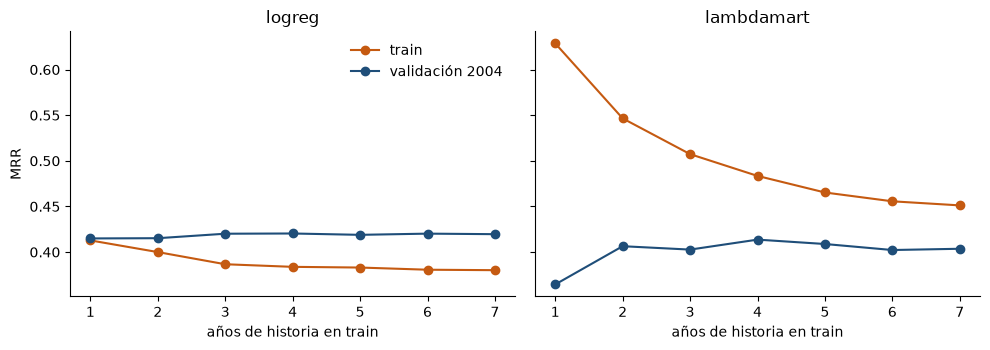

In [54]:
lc_models = [m for m in CFG["learning_curve_models"] if (RES / f"learning_curve_{m}.csv").exists()]
fig, axes = plt.subplots(1, len(lc_models), figsize=(5 * len(lc_models), 3.6), sharey=True)
axes = [axes] if len(lc_models) == 1 else axes
for ax, m in zip(axes, lc_models):
    lc = pd.read_csv(RES / f"learning_curve_{m}.csv").pivot(index="years", columns="part", values="mrr")
    ax.plot(lc.index, lc["train"], "o-", color="#c55a11", label="train")
    ax.plot(lc.index, lc["val"], "o-", color="#1f4e79", label="validación 2004")
    ax.set_title(m); ax.set_xlabel("años de historia en train"); ax.spines[["top", "right"]].set_visible(False)
    gap = lc["train"].iloc[-1] - lc["val"].iloc[-1]
    print(f"{m:11s}: MRR train {lc['train'].iloc[-1]:.3f} vs val {lc['val'].iloc[-1]:.3f} "
          f"→ brecha {gap:+.3f} con todos los años")
axes[0].set_ylabel("MRR"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Calibración (modelo propuesto)

LambdaMART devuelve puntajes sin escala. Se convierten en probabilidades con un softmax por carrera y una **temperatura** ajustada solo en validación. Un solo parámetro no cambia el orden (top-1, MRR y NDCG quedan iguales); solo afecta log loss, Brier y ECE.

Si los puntos caen sobre la diagonal, cuando el modelo dice "20 %" el caballo gana ~20 % de las veces.

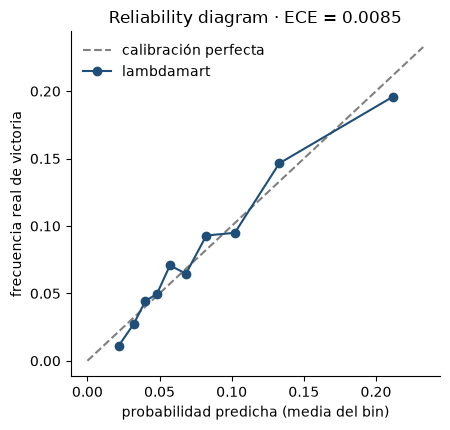

Temperatura ajustada en validación: T = 0.876


In [55]:
rel = pd.read_csv(RES / "val_reliability_lambdamart.csv")
fig, ax = plt.subplots(figsize=(4.6, 4.4))
lim = max(rel["p_mean"].max(), rel["freq"].max()) * 1.1
ax.plot([0, lim], [0, lim], ls="--", color="grey", label="calibración perfecta")
ax.plot(rel["p_mean"], rel["freq"], "o-", color="#1f4e79", label="lambdamart")
ax.set_xlabel("probabilidad predicha (media del bin)"); ax.set_ylabel("frecuencia real de victoria")
ax.set_title(f"Reliability diagram · ECE = {val.loc['lambdamart','ece']:.4f}")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print(f"Temperatura ajustada en validación: T = {val.loc['lambdamart','T']:.3f}")

## 5. Análisis de errores (modelo propuesto)

¿Dónde falla? Top-1 segmentado por tamaño del campo, por la cuota del ganador real y según si el modelo coincidió con el favorito del mercado.

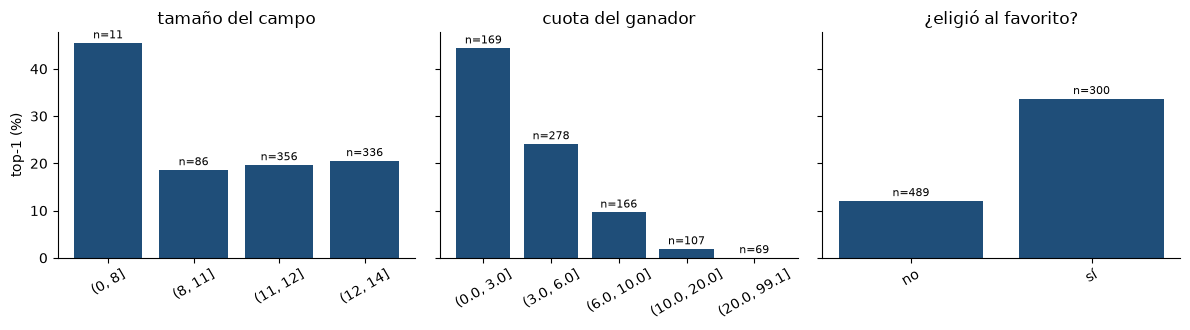

In [56]:
seg = {
    "tamaño del campo": "val_errors_lambdamart_by_field_size.csv",
    "cuota del ganador": "val_errors_lambdamart_by_winner_odds.csv",
    "¿eligió al favorito?": "val_errors_lambdamart_agrees_with_market.csv",
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (titulo, f) in zip(axes, seg.items()):
    d = pd.read_csv(RES / f)
    etiquetas = d.iloc[:, 0].astype(str).replace({"True": "sí", "False": "no"})
    ax.bar(etiquetas, 100 * d["mean"], color="#1f4e79")
    for i, (h, n) in enumerate(zip(100 * d["mean"], d["size"])):
        ax.text(i, h + 1, f"n={n}", ha="center", fontsize=8)
    ax.set_title(titulo); ax.tick_params(axis="x", rotation=30); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("top-1 (%)")
plt.tight_layout(); plt.show()

**Casos límite:** las carreras donde el modelo estaba más seguro de su elegido y se equivocó (falsos positivos caros), y los ganadores que el modelo dejó más abajo (falsos negativos). Son los casos a discutir en el reporte.

In [57]:
cols = ["race_id", "date", "field_size", "pick_prob", "pick_mkt_rank", "winner_pred_rank", "winner_odds"]
print("Fallos más confiados:")
display(pd.read_csv(RES / "val_confident_misses_lambdamart.csv")[cols].head(10))
print("Ganadores peor ubicados por el modelo:")
display(pd.read_csv(RES / "val_missed_winners_lambdamart.csv")[cols].head(10))

Fallos más confiados:


,race_id,date,field_size,pick_prob,pick_mkt_rank,winner_pred_rank,winner_odds
0,5507,2004-08-07,9,0.4767,1.0000,6.0000,37.0000
1,5563,2004-08-29,14,0.4751,1.0000,8.0000,4.1000
2,5742,2004-11-10,9,0.4457,1.0000,6.0000,3.3000
3,5356,2004-06-02,10,0.4204,1.0000,5.0000,14.0000
4,5678,2004-10-17,11,0.4067,1.0000,4.0000,3.8000
5,5452,2004-07-11,14,0.3981,1.0000,7.0000,7.4000
6,5322,2004-03-28,14,0.3887,2.0000,4.0000,5.8000
7,5413,2004-06-26,14,0.3821,1.0000,2.0000,3.8000
8,5115,2004-01-11,13,0.3791,2.0000,2.0000,2.6000
9,5242,2004-02-29,9,0.3764,1.0000,5.0000,20.0000


Ganadores peor ubicados por el modelo:


,race_id,date,field_size,pick_prob,pick_mkt_rank,winner_pred_rank,winner_odds
0,5856,2004-12-22,14,0.2202,1.0000,14.0000,11.0000
1,5273,2004-03-13,14,0.1428,1.0000,14.0000,43.0000
2,5526,2004-08-15,14,0.1835,1.0000,14.0000,79.0000
3,5298,2004-03-21,14,0.1466,2.0000,14.0000,9.5000
4,5715,2004-10-31,14,0.1494,8.0000,13.0000,14.0000
5,5772,2004-11-21,14,0.2034,1.0000,13.0000,34.0000
6,5766,2004-11-21,14,0.2231,8.0000,13.0000,6.7000
7,5806,2004-12-05,14,0.1134,2.0000,13.0000,8.8000
8,5197,2004-02-11,14,0.1814,9.0000,13.0000,16.0000
9,5607,2004-09-17,14,0.2057,1.0000,13.0000,3.9000


## 6. ¿Cuánto aporta el historial? (v0 vs. v1 con historial)

Solo se muestra si existe `results_v0/` (ver los comandos al inicio).

In [58]:
if (RES_V0 / "val_metrics.csv").exists():
    v0 = pd.read_csv(RES_V0 / "val_metrics.csv").set_index("model")
    comp = pd.DataFrame({
        "top-1 v0 %": 100 * v0["top1"], "top-1 v1 %": 100 * val["top1"],
        "MRR v0": v0["mrr"], "MRR v1": val["mrr"], "Δ MRR": val["mrr"] - v0["mrr"],
        "log loss v0": v0["log_loss"], "log loss v1": val["log_loss"],
    }).reindex(orden).drop(index=["random", "market"], errors="ignore")
    display(comp)
else:
    print("No hay results_v0/: correr el experimento con dataset_v0 y --out results_v0 para esta comparación.")

,top-1 v0 %,top-1 v1 %,MRR v0,MRR v1,Δ MRR,log loss v0,log loss v1
model,,,,,,,
logreg,18.3777,23.4474,0.3850,0.4196,0.0346,2.3737,2.3310
gbm_binary,18.6312,19.7719,0.3870,0.4104,0.0234,2.3627,2.3121
clogit,18.3777,22.8137,0.3800,0.4144,0.0344,2.3815,2.3421
lambdamart,21.4195,20.2788,0.3981,0.4036,0.0055,2.3593,2.3133


**Qué muestra la tabla.** De v0 a v1 cambian dos cosas a la vez: entran las cinco variables de historial y `gear_any`, y salen `jockey_id`, `trainer_id` y `horse_gear` (Parte 1, sección 4). La tabla mide ese cambio completo, no cada variable por separado.

- **Modelos lineales: son los que más ganan.** La regresión logística sube de 18.4 % a 23.4 % de top-1 (+5.1 puntos: 185 aciertos contra 145, de 789 carreras) y el logit condicional de 18.4 % a 22.8 % (+4.4). El MRR sube ≈ 0.035 en los dos.
- **Modelos de árboles: casi no cambian en top-1.** El GBM binario sube 1.1 puntos y LambdaMART baja 0.8 (163 aciertos contra 169, es decir, 6 carreras). Esa diferencia es menor que lo que LambdaMART varía solo por cambiar la semilla (entre ≈ 20.7 % y ≈ 22.3 %, Parte 3, sección 5b), así que no se puede leer como que el historial lo empeora.
- **En los cuatro modelos el MRR sube y el *log loss* baja**, LambdaMART incluido (MRR +0.013). El historial mejora en qué puesto queda el ganador y la calidad de las probabilidades, aunque no siempre cambie quién queda primero.

**Por qué puede pasar** (es una interpretación, la tabla no la demuestra). En v0 el jinete y el entrenador entran como identificadores. Los modelos lineales los reciben como una columna por cada uno (*one-hot*, agrupando los poco frecuentes), mientras que LightGBM maneja las categorías directamente: por eso LambdaMART ya partía de más arriba en v0 (21.4 %) y el historial le agrega poco. La tasa histórica le entrega al modelo lineal esa misma información en una sola columna numérica, actualizada carrera a carrera. Es coherente con SHAP (cuaderno 03): `jockey_win_rate` es la variable más importante de LambdaMART en v1.

**Consecuencia.** Con v1 los cuatro modelos quedan a menos de 4 puntos entre sí (19.8–23.4 %) y la regresión logística pasa a ser la mejor en validación. v1 es la tabla que se usó en el experimento final.

**Cautelas.**
- La constante *k* del historial se eligió con 2004, lo que le da a v1 una ventaja leve en validación. Aun así, v1 también supera a v0 en la validación cruzada dentro de train (años 2001–2003), en los cuatro modelos: por ejemplo, el MRR de la logística pasa de 0.368 a 0.386 y el de LambdaMART de 0.388 a 0.407 (`results_v0/tuning/` y `results/tuning/`, archivos `*_best.json`).
- La comparación es solo en validación. v0 nunca se evaluó en test: el test se usó una sola vez, con v1.

## 7. Test (2005)

Se evalúa **una sola vez**, al final, con `--stage final`. Mientras no exista `results/test_metrics.csv`, esta sección queda vacía a propósito.

In [59]:
if (RES / "test_metrics.csv").exists():
    t = pd.read_csv(RES / "test_metrics.csv").set_index("model").reindex(orden)
    display(t[["n_races", "top1", "top1_lo", "top1_hi", "top1_diff_vs_ref", "mrr", "ndcg@3", "log_loss", "brier_race"]])
else:
    print("Test aún no evaluado (correcto mientras se ajusta y se hace SHAP).")

,n_races,top1,top1_lo,top1_hi,top1_diff_vs_ref,mrr,ndcg@3,log_loss,brier_race
model,,,,,,,,,
random,470,0.0815,0.0804,0.0825,-0.2090,0.2326,0.2478,2.5184,0.9176
market,470,0.2904,0.2489,0.3330,NaN,0.4887,0.5497,2.1139,0.8439
logreg,470,0.2213,0.1851,0.2574,-0.0691,0.4037,0.4484,2.3629,0.8870
gbm_binary,470,0.1915,0.1574,0.2277,-0.0989,0.3883,0.4373,2.3603,0.8882
clogit,470,0.2191,0.1830,0.2574,-0.0713,0.3994,0.4448,2.3715,0.8890
lambdamart,470,0.2149,0.1787,0.2511,-0.0755,0.3934,0.4350,2.3678,0.8898


## 8. Análisis de resultados

### 8.1 Resultado en test (2005)

El test se evaluó una sola vez, con todas las decisiones de modelado congeladas. Son 470 carreras que ningún modelo vio durante el entrenamiento, la búsqueda de hiperparámetros ni la calibración.

| Modelo | top-1 test | IC 95 % | Aciertos de 470 | top-1 validación |
|---|---|---|---|---|
| Azar | 8.2 % | — | 38 | 8.1 % |
| Regresión logística | **22.1 %** | 18.5–25.7 % | 104 | 23.4 % |
| Logit condicional | 21.9 % | 18.3–25.7 % | 103 | 22.8 % |
| LambdaMART | 21.5 % | 17.9–25.1 % | 101 | 20.7 % |
| GBM binario | 19.2 % | 15.7–22.8 % | 90 | 19.8 % |
| Favorito del mercado | 29.0 % | 24.9–33.3 % | 136 | 33.1 % |
| Silverman (2012), referencia | 21.6 % | — | — | — |

**Contra el azar:** el mejor modelo acierta casi el triple (104 contra 38 carreras), y el intervalo de confianza queda muy por encima del 8 %. Los modelos aprendieron patrones reales de las carreras previas.

**Contra la literatura:** la regresión logística (22.1 %) queda al nivel del mejor resultado publicado para Hong Kong (Silverman, 21.6 %). No se puede afirmar que sea mejor, porque la diferencia está dentro del margen de error. Además, Silverman predice el caballo más rápido estimado y no el ganador oficial, así que la comparación es aproximada.

**Contra el mercado:** ningún modelo supera al favorito de las apuestas. La diferencia pareada es significativa en los cuatro modelos (por ejemplo, logística: −6.9 puntos, IC [−10.9, −3.1]). Las cuotas finales contienen información que no está en las variables previas a la carrera.

**Pregunta de investigación:** ordenar la carrera completa (LambdaMART) no superó a los modelos más simples. En test, LambdaMART (21.5 %) y la logística (22.1 %) son estadísticamente equivalentes. Es un resultado negativo, pero válido: con estas variables, la información del orden completo de llegada no aportó ventaja sobre predecir ganador / no ganador.

### 8.2 Generalización: de validación a test

La logística pasó de 23.4 % en validación a 22.1 % en test, una caída de 1.3 puntos. Era esperable, por dos razones:
- 2004 fue el año más predecible del período: incluso el mercado bajó de 33.1 % a 29.0 % en 2005.
- La constante *k* del historial y la temperatura de calibración se eligieron con 2004, lo que deja la validación levemente optimista. El test no tiene ese sesgo.

### 8.3 ¿Aprendió de verdad? Antes y después del entrenamiento

Con los pesos en cero (logística, logit condicional) o con cero árboles (GBM, LambdaMART), los cuatro modelos aciertan 64 de las 789 carreras de validación, exactamente lo mismo que el azar. Entrenados, aciertan entre 156 y 185 (`scripts/antes_despues.py`). En los modelos de árboles, el número de aciertos sube a medida que se agregan árboles.

### 8.4 Sobreajuste (curvas de aprendizaje, sección 3)

- **Regresión logística:** MRR de 0.380 en train y 0.420 en validación. No sobreajusta: generaliza igual o mejor de lo que rinde en los datos de entrenamiento.
- **LambdaMART:** MRR de 0.458 en train y 0.411 en validación, una brecha de 0.047. Memoriza parte del entrenamiento. Además, el MRR de validación se estanca alrededor de 0.41 desde los 2 años de historia: agregar más años no lo mejora.
- **Conclusión:** la limitación no está en la cantidad de datos ni en el ajuste de hiperparámetros, sino en la señal que tienen las variables previas a la carrera.

### 8.5 Análisis de errores (sección 5)

- **Según la cuota del ganador:** cuando gana un favorito (cuota ≤ 3), el modelo acierta el 47.9 %. Con cuota de 6 a 10, el 9.6 %. Con cuota mayor a 20, nunca acierta (0 de 69 carreras). El modelo falla sobre todo cuando gana un caballo que nadie esperaba, igual que el mercado.
- **Según si coincide con el mercado:** cuando el modelo elige al mismo favorito que las apuestas, acierta el 34.2 % (310 carreras). Cuando elige otro caballo, solo el 11.9 % (479 carreras). El modelo no encuentra ganadores que el mercado no vea.
- **Casos límite:** los fallos más confiados son carreras donde el modelo daba más de 40 % de probabilidad a un favorito que terminó perdiendo, y los peores falsos negativos son ganadores que el modelo ubicó en el último lugar de campos de 14 caballos.

### 8.6 Calibración (sección 4)

Las probabilidades de LambdaMART, calibradas con una temperatura T = 0.85 ajustada en validación, tienen un error de calibración (ECE) de 0.005: cuando el modelo dice "20 %", el caballo gana alrededor del 20 % de las veces. Esto permite usar las probabilidades directamente, por ejemplo para decidir si una apuesta conviene.

### 8.7 Robustez

- **Semilla:** con 5 semillas distintas, el top-1 de LambdaMART varía alrededor de un punto (Parte 3, sección 5b), menos que el intervalo de confianza. Se mantiene la semilla 42 para que los resultados sean reproducibles. Ninguna semilla cambia las conclusiones.
- **`gear_any`:** el análisis SHAP (Parte 3) encontró que esta variable cambia de comportamiento con el tiempo (*drift*). Quitarla mejora LambdaMART apenas +0.7 puntos en promedio, dentro del margen de error, así que se mantuvo y se documenta como hallazgo del control de calidad.

### 8.8 Limitaciones

- El test tiene 470 carreras, lo que da intervalos de unos ±3.6 puntos: diferencias pequeñas entre modelos no se pueden distinguir.
- Los datos llegan a 2005, y el mercado y las reglas de Hong Kong pueden haber cambiado desde entonces.
- Las cuotas se usan solo como referencia, nunca como variable, para medir lo que se puede predecir sin el mercado.

# Parte 3 · Explicabilidad (SHAP) del modelo propuesto

Esta parte explica **qué variables usa LambdaMART para ordenar a los caballos** y lo usa como **control de calidad**: si una variable inesperada dominara, podría ser una fuga que se nos pasó.

**Qué es SHAP.** Para cada caballo, el modelo da un puntaje (mayor = más probable que gane). SHAP reparte ese puntaje entre las 22 variables: cada una recibe un *aporte* positivo (lo sube en el ranking) o negativo (lo baja), y la suma de los aportes da exactamente el puntaje. Se basa en los valores de Shapley de teoría de juegos. LightGBM los calcula de forma exacta para árboles con `pred_contrib=True`, así que no hace falta la librería `shap`.

**Requisito:** haber corrido el entrenamiento, que deja `results/models.joblib`:

```bash
python src/build_dataset.py --version v1
python scripts/run_experiments.py --data data/processed/dataset_v1.parquet --stage dev
```

Todo se calcula sobre validación (2004).

In [60]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Raíz del repo (sirve si el cuaderno se abre desde notebooks/ o desde la raíz)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").is_dir())
RES = ROOT / "results"
FIG = RES / "figures"
FIG.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
from hkr import data as D

val = D.split(D.load(ROOT / "data/processed/dataset_v1.parquet"), "val")
m = joblib.load(RES / "models.joblib")["lambdamart"]["model"]
print(f"Validación: {len(val):,} caballos en {val.race_id.nunique()} carreras")
print(f"LambdaMART: {m.model_.n_estimators} árboles, {len(m.features)} variables")

Validación: 9,902 caballos en 789 carreras
LambdaMART: 163 árboles, 22 variables


## 1. Valores SHAP

`pred_contrib=True` devuelve una columna por variable más una última columna con el valor base (el puntaje promedio). Se verifica que los aportes sumen el puntaje del modelo: si no sumaran, la explicación no correspondería al modelo.

In [61]:
X = m.enc_.transform(val[m.features])          # mismo preprocesamiento que en el entrenamiento
contrib = m.model_.predict(X, pred_contrib=True)
shap_vals = pd.DataFrame(contrib[:, :-1], columns=m.features)

score = m.model_.predict(X)
assert np.allclose(contrib.sum(axis=1), score), "los aportes no suman el puntaje"
print("Los aportes SHAP suman exactamente el puntaje del modelo para los", len(score), "caballos.")
shap_vals.head()

Los aportes SHAP suman exactamente el puntaje del modelo para los 9902 caballos.


,horse_age,horse_country,horse_type,horse_rating,declared_weight,actual_weight,draw,venue,config,surface,...,horse_ratings,prize,race_class,field_size,horse_win_rate,jockey_win_rate,trainer_win_rate,horse_days_since_last,horse_no_history,gear_any
0,-0.0054,-0.0115,0.0001,-0.0324,-0.1170,0.0297,0.0835,-0.0113,0.0002,-0.0047,...,0.0102,-0.0048,-0.0000,-0.0148,-0.1992,-0.3419,-0.1146,0.0513,0.0000,-0.0205
1,0.0902,0.0266,0.0001,0.2788,-0.0044,0.0421,-0.1565,0.0078,0.0006,0.0001,...,0.0101,-0.0040,-0.0000,-0.0022,-0.1121,-0.3704,0.0162,0.0375,0.0000,0.1123
2,-0.0045,-0.0200,0.0012,-0.0331,0.0534,0.0826,0.1027,-0.0208,0.0122,-0.0014,...,-0.0458,0.0130,0.0004,-0.0071,0.2118,-0.2247,0.0393,0.0520,0.0000,-0.0187
3,0.0787,-0.0054,0.0003,0.3018,0.0038,0.1084,-0.1664,0.0253,0.0225,-0.0008,...,-0.0648,0.0022,-0.0001,-0.0016,-0.0213,0.6053,0.0319,0.0220,0.0000,0.1722
4,-0.0036,-0.0099,0.0013,-0.0355,-0.0334,0.0218,0.2337,-0.0179,0.0012,-0.0013,...,-0.0053,-0.0024,0.0001,-0.0166,0.0910,0.1365,0.0247,0.0426,0.0000,-0.0250


## 2. Familias de variables

Las 22 variables se agrupan en cuatro familias. La importancia de una variable es el promedio del valor absoluto de su aporte (cuánto mueve el puntaje, sin importar la dirección), y la de una familia es la suma de las de sus variables.

In [62]:
FAMILIAS = {
    "Historial": ["horse_win_rate", "jockey_win_rate", "trainer_win_rate",
                  "horse_days_since_last", "horse_no_history"],
    "Caballo": ["horse_age", "horse_country", "horse_type", "horse_rating",
                "declared_weight", "actual_weight", "gear_any"],
    "Portón": ["draw"],
    "Carrera y pista": ["venue", "config", "surface", "distance", "going",
                        "horse_ratings", "prize", "race_class", "field_size"],
}
familia_de = {v: f for f, vs in FAMILIAS.items() for v in vs}
# Toda variable del modelo debe estar en exactamente una familia
assert sorted(familia_de) == sorted(m.features), set(m.features) ^ set(familia_de)

LambdaMART solo ordena caballos dentro de cada carrera: si una variable sube por igual el puntaje de todos los caballos de una carrera, no cambia quién queda primero. Por eso, además de la importancia global (la que pide la guía), se calcula la importancia **dentro de la carrera**: a cada aporte se le resta el promedio de su carrera, y queda solo la parte que distingue a un caballo de sus rivales.

In [63]:
codigos = D.race_codes(val)
shap_rel = shap_vals - shap_vals.groupby(codigos).transform("mean")   # aporte relativo a los rivales

imp = pd.DataFrame({
    "familia": pd.Series(familia_de),
    "global": shap_vals.abs().mean(),
    "dentro_carrera": shap_rel.abs().mean(),
})
imp["global_%"] = 100 * imp["global"] / imp["global"].sum()
imp["dentro_carrera_%"] = 100 * imp["dentro_carrera"] / imp["dentro_carrera"].sum()
imp = imp.sort_values("global", ascending=False)
imp.to_csv(RES / "shap_importance_lambdamart.csv", index_label="variable")
imp

,familia,global,dentro_carrera,global_%,dentro_carrera_%
jockey_win_rate,Historial,0.2827,0.2837,23.2891,27.8063
horse_rating,Caballo,0.1786,0.0816,14.7135,7.9951
horse_win_rate,Historial,0.1613,0.1368,13.2857,13.4079
draw,Portón,0.1305,0.1289,10.7496,12.6296
gear_any,Caballo,0.0877,0.0467,7.2217,4.5720
trainer_win_rate,Historial,0.0863,0.0801,7.1073,7.8515
horse_days_since_last,Historial,0.0625,0.0573,5.1481,5.6120
horse_age,Caballo,0.0546,0.0504,4.4947,4.9415
declared_weight,Caballo,0.0478,0.0455,3.9406,4.4599
actual_weight,Caballo,0.0365,0.0351,3.0079,3.4371


In [64]:
fam = imp.groupby("familia")[["global_%", "dentro_carrera_%"]].sum().sort_values("global_%", ascending=False)
fam

,global_%,dentro_carrera_%
familia,,
Historial,48.8301,54.6776
Caballo,35.0009,27.2758
Portón,10.7496,12.6296
Carrera y pista,5.4193,5.4170


## 3. Gráficos

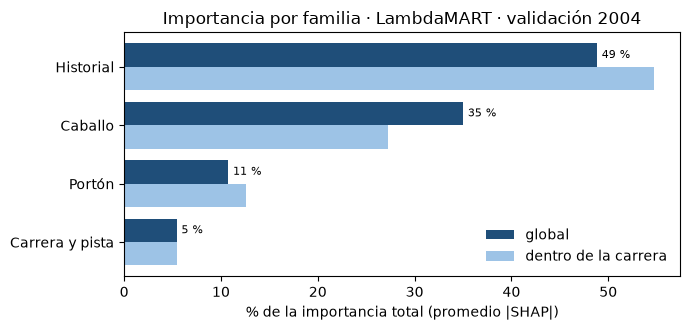

In [65]:
fig, ax = plt.subplots(figsize=(7, 3.4))
y = np.arange(len(fam))
ax.barh(y - 0.2, fam["global_%"], height=0.4, color="#1f4e79", label="global")
ax.barh(y + 0.2, fam["dentro_carrera_%"], height=0.4, color="#9dc3e6", label="dentro de la carrera")
ax.set_yticks(y, fam.index)
ax.invert_yaxis()
ax.set_xlabel("% de la importancia total (promedio |SHAP|)")
ax.set_title("Importancia por familia · LambdaMART · validación 2004")
ax.legend(loc="lower right", frameon=False)
for i, v in enumerate(fam["global_%"]):
    ax.text(v + 0.5, i - 0.2, f"{v:.0f} %", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "shap_familias.png", dpi=150)
plt.show()

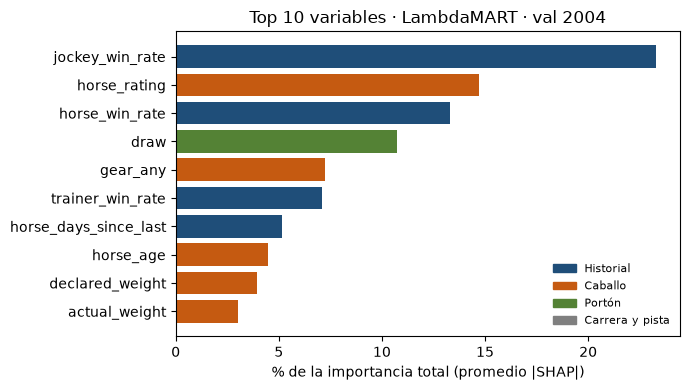

In [66]:
COLORES = {"Historial": "#1f4e79", "Caballo": "#c55a11", "Portón": "#548235", "Carrera y pista": "#7f7f7f"}
top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index, top["global_%"], color=[COLORES[f] for f in top["familia"]])
ax.set_xlabel("% de la importancia total (promedio |SHAP|)")
ax.set_title("Top 10 variables · LambdaMART · val 2004")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORES.values()]
ax.legend(handles, COLORES.keys(), loc="lower right", frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "shap_top10.png", dpi=150)
plt.show()

## 4. ¿En qué dirección empuja cada variable?

La importancia dice cuánto pesa una variable, no hacia dónde. Para las variables numéricas más importantes, se agrupan los caballos en quintiles del valor de la variable y se grafica el aporte SHAP promedio de cada grupo. Esto permite revisar si el efecto tiene sentido para alguien que sabe de carreras.

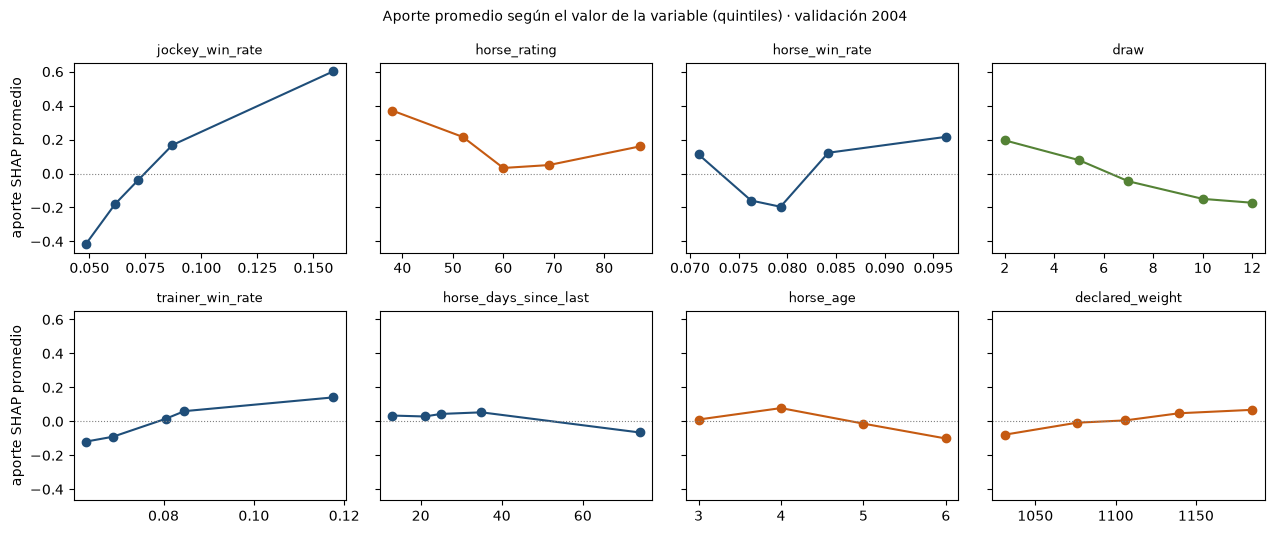

In [67]:
NUM = ["jockey_win_rate", "horse_rating", "horse_win_rate", "draw",
       "trainer_win_rate", "horse_days_since_last", "horse_age", "declared_weight"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.4), sharey=True)
for ax, v in zip(axes.flat, NUM):
    x = val[v].astype(float)
    grupos = pd.qcut(x, 5, duplicates="drop")
    media = shap_vals[v].groupby(grupos.values, observed=True).mean()
    centro = x.groupby(grupos.values, observed=True).median()
    ax.plot(centro, media, "o-", color=COLORES[familia_de[v]])
    ax.axhline(0, color="grey", lw=0.8, ls=":")
    ax.set_title(v, fontsize=9)
axes[0, 0].set_ylabel("aporte SHAP promedio")
axes[1, 0].set_ylabel("aporte SHAP promedio")
fig.suptitle("Aporte promedio según el valor de la variable (quintiles) · validación 2004", fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "shap_direccion.png", dpi=150)
plt.show()

`horse_win_rate` y `horse_rating` tienen una curva pronunciada o forma de U/V. La razón es que mezclan dos cosas: el nivel del caballo y la clase de la carrera (los caballos de tasa y rating bajos corren en carreras de clase baja, contra rivales igual de flojos). Para separarlas, se mide cada caballo contra los rivales de su carrera** (valor menos el promedio de la carrera) y se compara el aporte SHAP con la tasa de victoria real.

In [68]:
filas = {}
for v in ["horse_win_rate", "horse_rating"]:
    rel = val[v] - val[v].groupby(codigos).transform("mean")
    q = pd.qcut(rel, 5, labels=["Q1 (más bajo de su carrera)", "Q2", "Q3", "Q4", "Q5 (más alto)"])
    filas[(v, "SHAP promedio")] = shap_vals[v].groupby(q.values, observed=True).mean()
    filas[(v, "gana % real")] = 100 * val["won"].groupby(q.values, observed=True).mean()
pd.DataFrame(filas).T.round(2)

Q1 (más bajo de su carrera)      Q2      Q3  \
horse_win_rate SHAP promedio                       0.0000 -0.0600 -0.0700   
               gana % real                         6.8100  6.5700  7.2200   
horse_rating   SHAP promedio                       0.2400  0.1400  0.1700   
               gana % real                         6.9700  7.7500  8.9300   

                                 Q4  Q5 (más alto)  
horse_win_rate SHAP promedio 0.0400         0.1900  
               gana % real   8.5400        10.7500  
horse_rating   SHAP promedio 0.1700         0.1200  
               gana % real   7.8200         8.4400

In [69]:
# Las dos binarias: aporte promedio cuando valen 0 y cuando valen 1
for v in ["gear_any", "horse_no_history"]:
    print(v, shap_vals[v].groupby(val[v].values).mean().round(3).to_dict(),
          "· caballos:", val[v].value_counts().sort_index().to_dict())

gear_any {0: -0.018, 1: 0.109} · caballos: {0: 2337, 1: 7565}
horse_no_history {0: 0.0, 1: 0.0} · caballos: {0: 9478, 1: 424}


## 5. Control de calidad

Tres revisiones para descartar fugas o efectos raros.

**a) Variables de la carrera.** Las variables de "Carrera y pista" (premio, distancia, clase, tamaño del campo…) son iguales para todos los caballos de una carrera, así que por sí solas no pueden decir quién gana. Si alguna dominara como tal no sería algo esperado y habría que revisar a detalle.

In [70]:
fam.loc["Carrera y pista"]

global_%           5.4193
dentro_carrera_%   5.4170
Name: Carrera y pista, dtype: float64

b) `gear_any` sube el puntaje. Llevar equipo (anteojeras, lengüeta, etc.) empuja al caballo hacia arriba: es la 5.ª variable. Se revisa, año por año, cuántos caballos llevan equipo y cuánto ganan con y sin él.

In [71]:
full = D.load(ROOT / "data/processed/dataset_v1.parquet")
anual = (full.assign(año=full["date"].dt.year)
             .groupby(["año", "gear_any"])["won"].agg(["mean", "size"]).unstack("gear_any"))
gear_por_año = pd.DataFrame({
    "% con equipo": 100 * anual[("size", 1)].fillna(0) / anual["size"].sum(axis=1),
    "gana con equipo %": 100 * anual[("mean", 1)],
    "gana sin equipo %": 100 * anual[("mean", 0)],
    "split": full.groupby(full["date"].dt.year)["split"].first(),
}).round(1)
gear_por_año

,% con equipo,gana con equipo %,gana sin equipo %,split
1997,0.0000,0.0000,8.0000,train
1998,0.4000,12.9000,7.9000,train
1999,1.3000,11.5000,8.0000,train
2000,4.2000,12.6000,7.8000,train
2001,12.9000,10.9000,7.6000,train
2002,30.0000,11.5000,6.6000,train
2003,53.7000,9.9000,5.8000,train
2004,76.4000,8.1000,7.6000,val
2005,79.5000,8.1000,7.8000,test


**Qué muestra la tabla.** El registro de equipo pasa de 0 % en 1997 a casi 80 % en 2004–2005. En train, pocos caballos llevan equipo y esos ganan más (≈ 11 % contra ≈ 7 %), así que el modelo aprende "equipo = mejor". Pero en 2004 y 2005 casi todos llevan equipo y ganan igual que los que no (≈ 8 % ambos): **la relación que aprendió el modelo ya no se cumple**. No es una fuga (el equipo se declara antes de la carrera), sino un cambio en la distribución de los datos con el tiempo (*drift*), sea porque se popularizó el equipo o porque cambió la forma de registrarlo.

**Prueba rápida:** se reentrena LambdaMART con los mismos hiperparámetros, con y sin `gear_any`, con varias semillas, y se compara en validación. Solo usa train y validación; el modelo oficial de `results/` no cambia. Tarda unos segundos por semilla.

In [72]:
from hkr import metrics as M
from hkr.models import LambdaMART

tr = D.split(full, "train")
params = joblib.load(RES / "models.joblib")["lambdamart"]["params"]
sin_gear = [f for f in m.features if f != "gear_any"]
filas = []
for seed in [42, 1, 2, 3, 4]:
    s_con = LambdaMART(m.features, params, seed).fit(tr).score(val)
    s_sin = LambdaMART(sin_gear, params, seed).fit(tr).score(val)
    d = M.bootstrap_ci(val, s_sin, s_con)          # diferencia pareada en las mismas carreras
    filas.append({"semilla": seed,
                  "top-1 con gear %": 100 * M.top1_accuracy(val, s_con),
                  "top-1 sin gear %": 100 * M.top1_accuracy(val, s_sin),
                  "Δ top-1 (puntos)": 100 * d["top1_diff_vs_ref"],
                  "IC 95 % Δ": f"[{100 * d['top1_diff_lo']:+.1f}, {100 * d['top1_diff_hi']:+.1f}]",
                  "MRR con": M.mrr(val, s_con), "MRR sin": M.mrr(val, s_sin)})
abl = pd.DataFrame(filas).set_index("semilla")
display(abl.round(3))
print(f"Promedio: Δ top-1 = {abl['Δ top-1 (puntos)'].mean():+.2f} puntos, "
      f"Δ MRR = {(abl['MRR sin'] - abl['MRR con']).mean():+.4f}; "
      f"sin gear es mejor en {(abl['Δ top-1 (puntos)'] > 0).sum()} de {len(abl)} semillas")

,top-1 con gear %,top-1 sin gear %,Δ top-1 (puntos),IC 95 % Δ,MRR con,MRR sin
semilla,,,,,,
42,20.2790,21.4200,1.1410,"[-0.9, +3.2]",0.4040,0.4150
1,21.6730,22.9400,1.2670,"[-0.6, +3.2]",0.4120,0.4200
2,21.6730,21.5460,-0.1270,"[-2.0, +1.8]",0.4130,0.4130
3,21.4200,22.0530,0.6340,"[-1.1, +2.4]",0.4090,0.4160
4,21.5460,21.8000,0.2530,"[-1.8, +2.3]",0.4110,0.4150


Promedio: Δ top-1 = +0.63 puntos, Δ MRR = +0.0060; sin gear es mejor en 4 de 5 semillas


**c) `horse_rating` pierde peso dentro de la carrera.** Su importancia global es alta, pero baja a la mitad al medirla dentro de la carrera. En Hong Kong las carreras son *handicap*: los caballos de una carrera tienen ratings parecidos (por eso existe la banda `horse_ratings`) y el de mayor rating carga más peso. Se revisa cuánto gana, en la realidad, el caballo con el rating más alto de su carrera.

In [73]:
rk = val.groupby("race_id")["horse_rating"].rank(ascending=False, method="first")
print("Tasa de victoria en validación según la posición del caballo por rating dentro de su carrera:")
print(val.groupby(rk.values)["won"].mean().head(6).round(3).rename("tasa").to_frame().T)
print(f"\nTasa promedio (1/n): {(1 / val.groupby('race_id').size()).mean():.3f}")
print("Aporte SHAP promedio de horse_rating por clase de carrera:")
print(shap_vals["horse_rating"].groupby(val["race_class"].values).mean().round(2).to_frame("SHAP").T)

Tasa de victoria en validación según la posición del caballo por rating dentro de su carrera:
      1.0000  2.0000  3.0000  4.0000  5.0000  6.0000
tasa  0.0980  0.0810  0.0950  0.0720  0.0790  0.0720

Tasa promedio (1/n): 0.081
Aporte SHAP promedio de horse_rating por clase de carrera:
         0      1      2      3      4      5      6      11     12     13
SHAP 0.1700 0.2500 0.1200 0.0400 0.1800 0.4000 0.2200 0.2300 0.3300 0.2500


## 6. Hallazgos

> Los porcentajes se refieren a la importancia global salvo que se diga lo contrario; pueden variar unas décimas entre corridas en máquinas distintas.

1. **El historial domina, y el jinete es lo más importante.** La familia *Historial* concentra cerca de la mitad de la importancia, y `jockey_win_rate` es la variable número uno (≈ 21 % global, ≈ 26 % dentro de la carrera), con un efecto casi lineal: mejor tasa del jinete, mayor puntaje. Tiene sentido: en Hong Kong los mejores jinetes eligen montas y se suben a los mejores caballos, así que su tasa resume información del caballo y del entrenador. Es coherente con la comparación v0 vs. v1, donde agregar el historial fue lo que más mejoró a los modelos.

2. **Los efectos tienen la dirección que esperaría alguien que sabe de carreras.** Cajón bajo (`draw`, cerca del riel) ayuda; es la 4.ª variable y su efecto es casi una recta decreciente. Mucho tiempo sin correr (`horse_days_since_last`) y más edad (desde los 5 años) restan. Mayor tasa del entrenador suma. La tasa del caballo tiene forma de U en el gráfico global, pero es porque se mezcla con la clase de la carrera: comparada contra los rivales de su carrera, más tasa da más puntaje y el caballo gana más en la realidad (de ≈ 7 % a ≈ 11 %). Ninguna variable importante empuja en una dirección absurda.

3. **No hay señales de fuga.** Las variables de *Carrera y pista* suman poco (≈ 7.5 %) y ninguna está entre las primeras; `prize`, `race_class` y `field_size` están cerca de cero. Si el modelo estuviera usando información del resultado, lo esperable sería que una variable rara o de la carrera dominara, y no pasa. Esto complementa las pruebas automáticas contra fuga de `tests/`.

4. **`horse_rating` pesa menos de lo que parece.** Es la 2.ª variable global (≈ 15 %), pero dentro de la carrera baja a menos de la mitad (≈ 7.5 %), y su efecto no es monótono (tiene forma de U). En las carreras *handicap* los rivales tienen ratings parecidos y el de mayor rating carga más peso, así que el rating más alto de la carrera gana poco más que el promedio. El modelo usa el rating sobre todo para ubicar la **clase** de la carrera, no para elegir al ganador. Además, dentro de la carrera el modelo favorece un poco al de **menor** rating (que carga menos peso), mientras que en la realidad ese caballo gana algo menos: es un punto donde el modelo podría estar equivocándose. **Accionable:** para el ranking conviene reportar la importancia dentro de la carrera, y una variable "rating relativo a la carrera" podría ser más útil que el rating crudo.

5. **`gear_any` es la variable problemática: aprende una regla que dejó de cumplirse.** Es la 5.ª variable (≈ 8 %) y sube el puntaje de quien lleva equipo. Pero el registro de equipo pasa de 0 % de los caballos en 1997 a ≈ 80 % en 2004–2005, y la ventaja de llevarlo desaparece: en train los caballos con equipo ganan más, en validación ganan igual que los demás. No es una fuga, es un cambio de la distribución con el tiempo (*drift*), justo el tipo de problema en los datos que SHAP permite detectar. Al quitarla, LambdaMART mejora en promedio (sección 5b), aunque la diferencia cabe dentro del ruido. **Accionable:** quitar `gear_any` o reemplazarla por una variable estable (por ejemplo, "cambió de equipo respecto a su carrera anterior"); la decisión debe tomarse antes de evaluar test.

6. **Variables que casi no aportan.** `surface`, `horse_type`, `horse_no_history`, `going` y `race_class` suman menos de 1.5 % entre todas; son candidatas a quitarse en un estudio de ablación. `horse_no_history` sale casi en cero porque es redundante: un debutante ya se reconoce porque su `horse_win_rate` es exactamente el prior y `horse_days_since_last` está vacío.

**Nota sobre el ruido:** en la prueba de la sección 5b, el mismo LambdaMART da entre ≈ 20.7 % y ≈ 22.3 % de top-1 solo por cambiar la semilla. Diferencias de uno o dos puntos entre modelos deben leerse con los intervalos de confianza, no con el número suelto.

**Regla de ética:** los resultados se reportan por familia y por variable, nunca por jinete o entrenador individual.

## Declaración de uso de IA

El equipo usó herramientas de IA como apoyo en esta entrega. En qué partes, con qué propósito y qué se verificó manualmente está declarado, por integrante, en `DECLARACION_IA.md` (raíz del repositorio).